<a href="https://colab.research.google.com/github/abnercardozo/laborat-rio-python-/blob/main/C%C3%B3pia_de_NumPy_NDArray_BI_AN1tN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NumPy — NDArray: BI - Clube de Vantagens

## Objetivos de aprendizagem
Carregar um array NumPy, reconhecer suas dimensões, selecionar linhas e colunas, formatar relatórios com `for ... in` e `enumerate`, calcular estatísticas e resolver consultas com vetorização, indexação booleana e indexação por arrays de inteiros.

## Preparação da aula
Coloque `dataset.npy` na mesma pasta deste notebook e execute as células em ordem. No Google Colab, envie o arquivo pela aba **Arquivos** antes de executar a etapa 2. O notebook usa somente NumPy e a biblioteca padrão do Python. Se o ambiente não tiver NumPy, instale-o com `%pip install numpy` em uma célula separada.

Os três exercícios de fixação têm **células de código vazias**, reservadas à resolução em aula. Nenhum exemplo posterior depende das respostas desses exercícios.

## Roteiro
1. Importação e conceito de `ndarray`.
2. Carregamento, dicionário e saída formatada com `in` e `enumerate`.
3. Dimensões: `len` e `shape`.
4. Fatiamento crescente e decrescente.
5. Mínimo, máximo, soma e média.
6. Vetorização.
7. Indexação booleana.
8. Indexação sofisticada (fancy indexing).

Os exemplos são autorais e usam exclusivamente o dataset Clube de Vantagens. As fontes estão ao final.

# 1. Importação da biblioteca
**NumPy** significa *Numerical Python*. Sua estrutura central é o `ndarray` (*N-dimensional array*), um array de dimensão arbitrária e elementos de um mesmo tipo físico (`dtype`). Neste estudo, usamos uma matriz de duas dimensões: linhas representam sócios e colunas representam atributos.

`np` é o apelido convencional da biblioteca. Importar não carrega o dataset: apenas disponibiliza as funções.

In [ ]:
import numpy as np

print("Versão do NumPy:", np.__version__)

Versão do NumPy: 2.4.6


# 2. Carregamento do arquivo com `np.load`
`np.load("dataset.npy")` lê o arquivo binário e recupera os valores, o formato e o tipo do array. O arquivo `.npy` não contém os nomes das colunas; sua interpretação depende do dicionário de dados.

Link: [dataset.npy](https://drive.google.com/file/d/10RhbESCHxq8V7s1ufkuGA2lEKnzJfNV1/view?usp=sharing)

In [ ]:
dataset = np.load("dataset.npy")

print("Estrutura:", type(dataset))
print("Tipo físico:", dataset.dtype)
print("Linhas e colunas:", dataset.shape)

Estrutura: <class 'numpy.ndarray'>
Tipo físico: float64
Linhas e colunas: (1000, 5)


## 2.1 Dicionário de dados

In [ ]:
dataset

array([[5.60600e+03, 1.00000e+00, 0.00000e+00, 2.45112e+03, 0.00000e+00],
       [1.63900e+03, 2.00000e+00, 9.99900e+03, 5.80070e+02, 1.00000e+00],
       [3.10200e+03, 2.00000e+00, 2.29200e+03, 1.59303e+03, 0.00000e+00],
       ...,
       [4.26800e+03, 2.00000e+00, 6.21400e+03, 1.39249e+03, 0.00000e+00],
       [3.80000e+03, 1.00000e+00, 2.13400e+03, 7.46410e+02, 0.00000e+00],
       [9.25100e+03, 1.00000e+00, 4.22000e+03, 2.38289e+03, 0.00000e+00]],
      shape=(1000, 5))

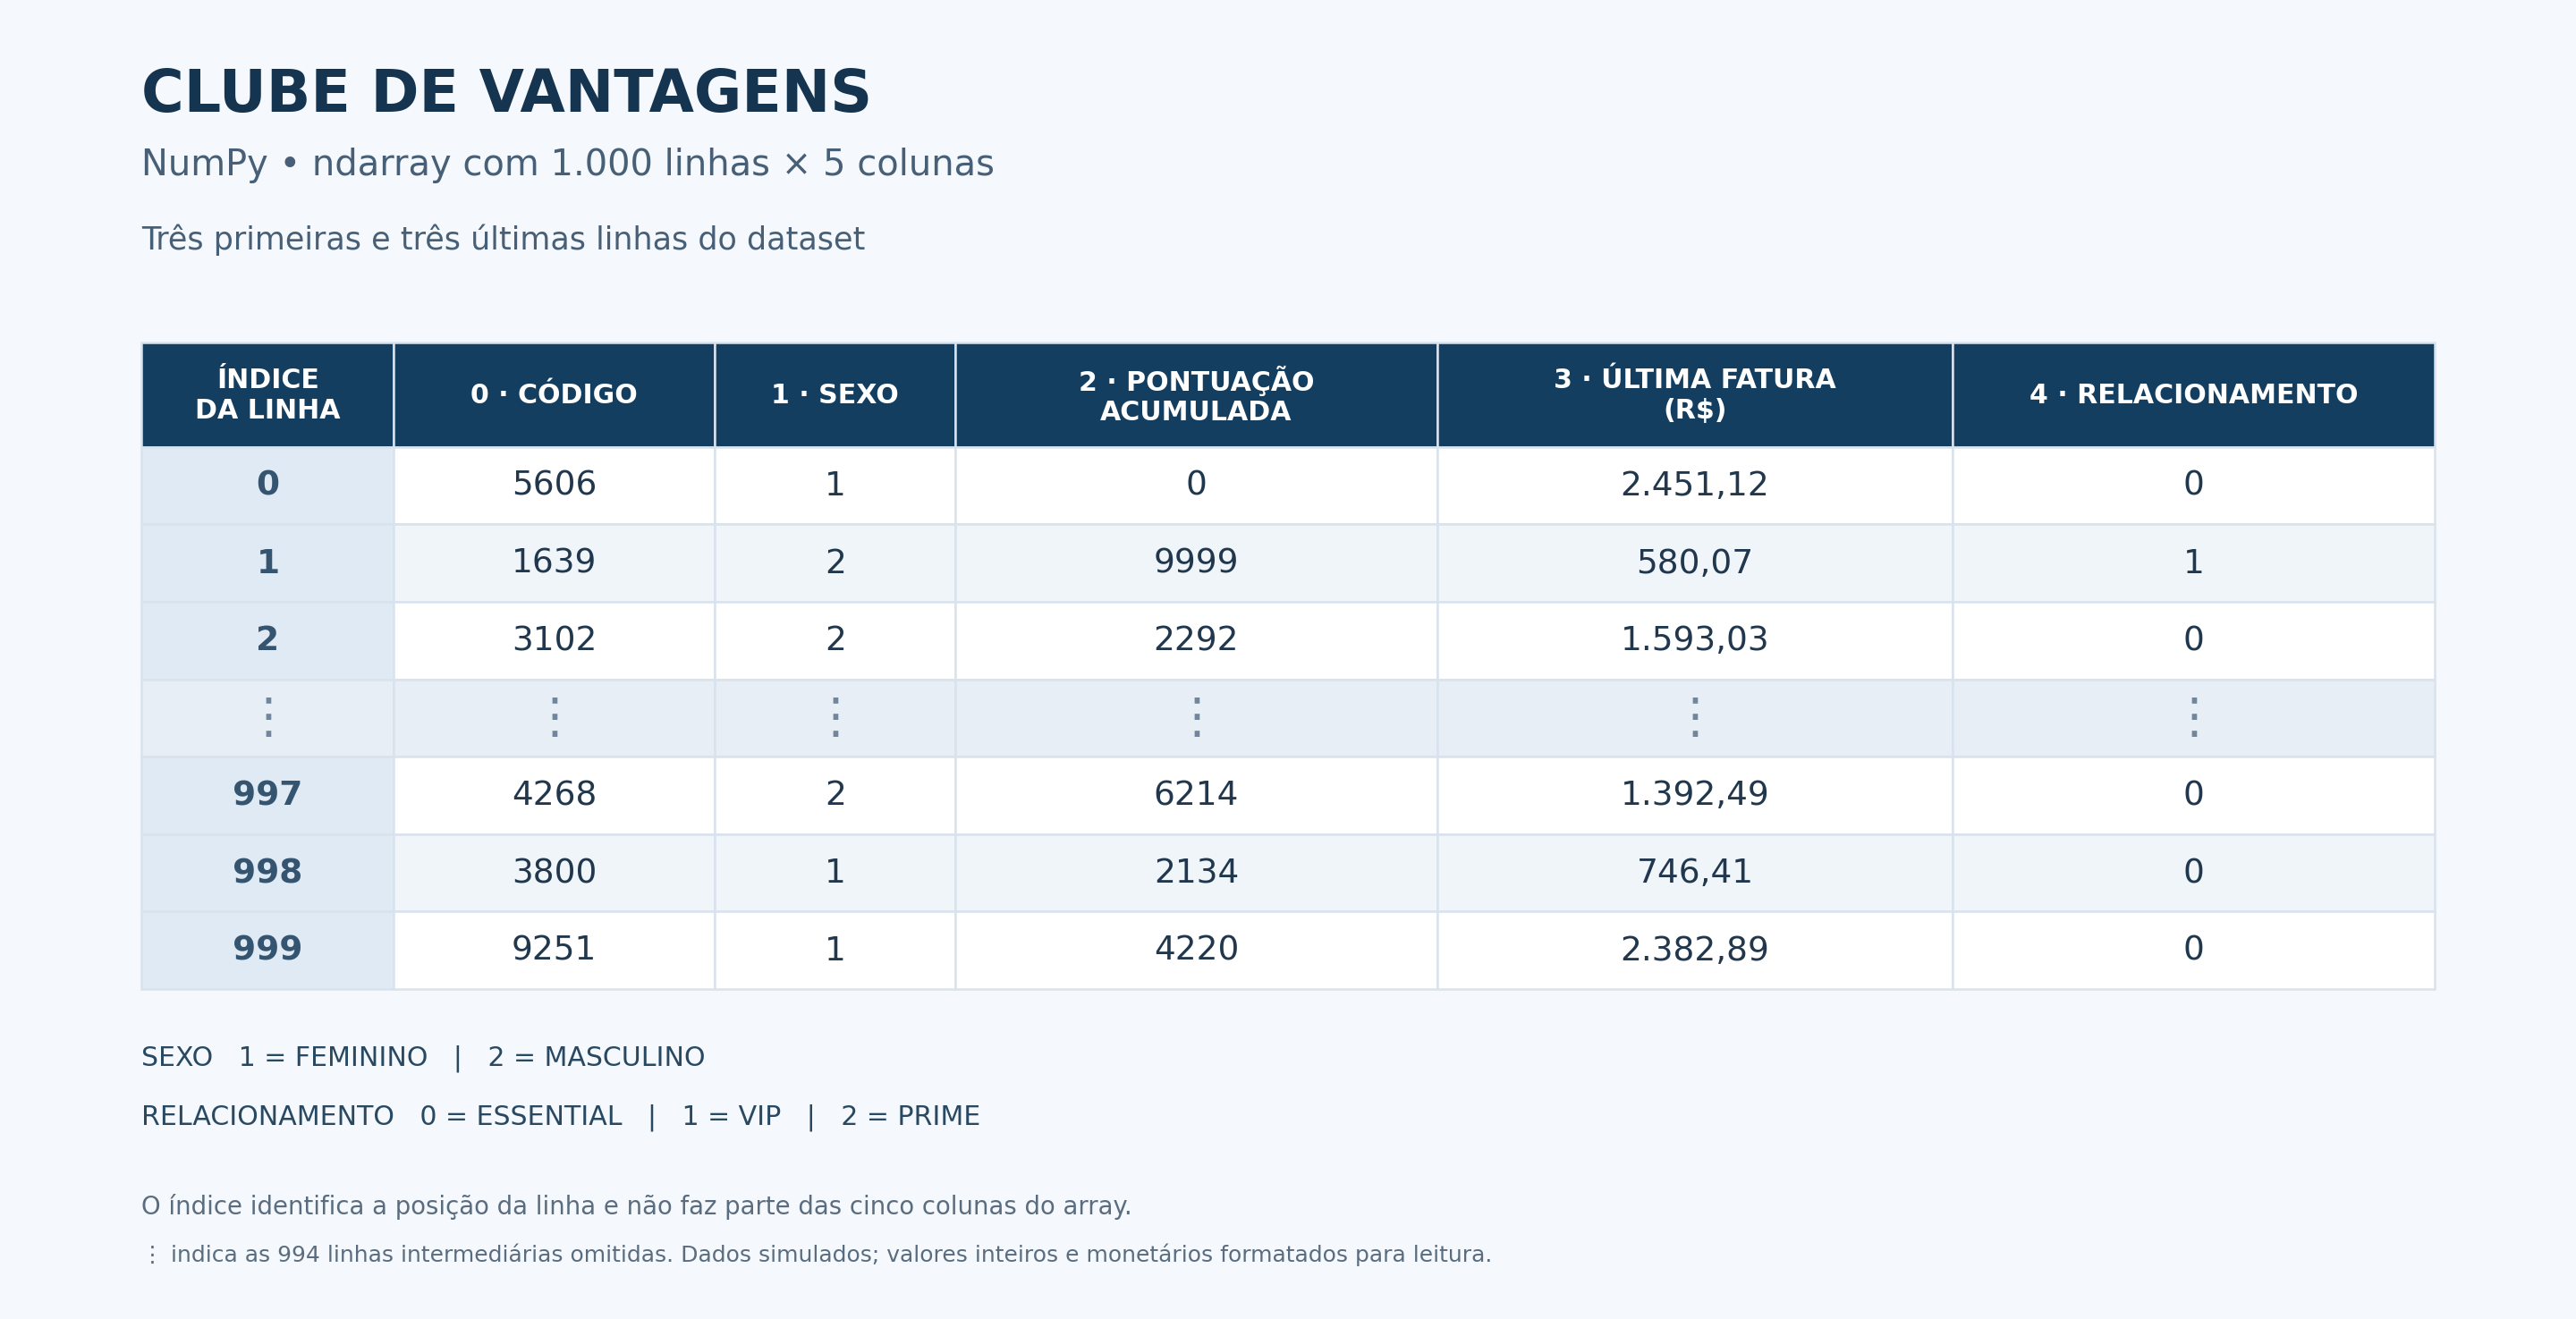

Dataset simulado para ensino de NumPy. Cada linha representa um sócio fictício; não há nomes ou dados pessoais reais.

- **Arquivo:** `dataset.npy` (formato binário NumPy, sem cabeçalho textual).
- **Estrutura:** `ndarray` bidimensional, 1.000 linhas × 5 colunas; índices de linha de 0 a 999.
- **Tipo físico:** `float64` em todas as células; um array numérico comum tem um único `dtype`.
- **Ausências:** nenhuma. Zero em pontuação ou fatura é um valor válido.

| Índice | Coluna | Significado e tipo conceitual | Domínio / unidade | Regras |
|:---:|:---|:---|:---|:---|
| 0 | CÓDIGO | Identificador; qualitativa nominal, representada por inteiro | 1000 a 9999 | Quatro dígitos, aleatório, único; linhas sem ordenação por código |
| 1 | SEXO | Categoria nominal, codificada por inteiro | 1 = FEMININO; 2 = MASCULINO | Codificação binária conforme o escopo didático solicitado |
| 2 | PONTUAÇÃO ACUMULADA | Quantitativa discreta; inteiro | 0 a 9999 pontos | De um a quatro dígitos, incluindo zero; repetições permitidas |
| 3 | ÚLTIMA FATURA — CARTÃO DE CRÉDITO | Quantitativa, registrada com duas casas decimais | R$ 0,00 a R$ 15.000,00 | Não negativa; repetições permitidas; zero indica ausência de cobrança na última fatura |
| 4 | RELACIONAMENTO | Categoria ordinal, codificada por inteiro | 0 = ESSENTIAL; 1 = VIP; 2 = PRIME | Hierarquia de categorias; códigos não representam distâncias numéricas equivalentes |


## 2.2 Nomes para os índices das colunas
Os nomes abaixo são constantes por convenção e tornam as consultas mais legíveis. Eles não alteram o arquivo e não são cabeçalhos dentro do array.

In [ ]:
# CONSTANTES - COLUNAS:

CODIGO = 0
SEXO = 1
PONTUACAO = 2
FATURA = 3
RELACIONAMENTO = 4

# CONSTANTES - CODIFICAÇÃO:
FEMININO, MASCULINO = 1, 2
ESSENTIAL, VIP, PRIME = 0, 1, 2

print("Código do primeiro sócio:", int(dataset[0, CODIGO]))
print(f"Última fatura: R$ {dataset[0, FATURA]:.2f}")

# LISTA HOMOGÊNEA: Rótulos para apresentar os códigos das categorias nos relatórios.
rotulos_sexo = ["", "FEMININO", "MASCULINO"]
rotulos_relacionamento = ["ESSENTIAL", "VIP", "PRIME"]

Código do primeiro sócio: 5606
Última fatura: R$ 2451.12


## 2.3 `in`: verificar se um valor está presente
`in` é uma palavra reservada de Python. Como **operador de pertinência**, verifica se um valor está presente em uma coleção e retorna `True` ou `False`. `not in` verifica a ausência.

```python
valor in colecao
valor not in colecao
```

Para consultar um código de sócio, pesquise apenas na coluna CÓDIGO (`dataset[:, CODIGO]`).

Assim, a consulta não confunde códigos com valores de outras colunas. `in` responde se o valor existe; não informa sua posição e não seleciona linhas.

In [ ]:
codigo_consultado = 5606

if codigo_consultado in dataset[:, CODIGO]:
    print(f"Sócio de código {codigo_consultado}: cadastrado.")
else:
    print(f"Sócio de código {codigo_consultado}: não encontrado.")

print("Existe sócio PRIME?", PRIME in dataset[:, RELACIONAMENTO])

Sócio de código 5606: cadastrado.
Existe sócio PRIME? True


## 2.4 `for ... in`: percorrer as linhas para exibir resultados
Em uma instrução `for`, a palavra `in` faz parte da sintaxe de iteração. Esse uso percorre elementos; não é um teste de pertinência.

```python
for elemento in colecao:
    print(elemento)
```

Ao percorrer uma matriz NumPy, recebemos uma linha por vez. No exemplo, `socio` contém os cinco atributos de um sócio. O laço apresenta as cinco primeiras linhas, com código inteiro e fatura com duas casas decimais.

In [ ]:
for socio in dataset[:5]:
  #print(f"Código: {int(socio[CODIGO])} | Última fatura: R$ {socio[FATURA]:.2f}")
  print(f"Código: {socio[CODIGO]: .0f} | Última fatura: R$ {socio[FATURA]:.2f}")

Código:  5606 | Última fatura: R$ 2451.12
Código:  1639 | Última fatura: R$ 580.07
Código:  3102 | Última fatura: R$ 1593.03
Código:  1972 | Última fatura: R$ 0.00
Código:  5486 | Última fatura: R$ 809.10


## 2.5 `enumerate`: contador e elemento em cada repetição
`enumerate` é uma função embutida de Python. A cada repetição, fornece um contador e o elemento correspondente.

```python
for contador, elemento in enumerate(colecao):
    print(contador, elemento)
```

O contador começa em zero por padrão. Para exibir uma numeração de relatório a partir de 1, usamos `contador + 1` no `print`. O contador continua começando em zero.

Como informação complementar, o parâmetro opcional `start` permite alterar o início da contagem. Ele não será utilizado nos exemplos deste notebook.

**Atenção ao significado:** no recorte `dataset[:5]`, o contador padrão coincide com os índices originais 0 a 4. Após filtrar, ordenar ou recortar a partir de outra posição, o contador representa a posição na sequência percorrida. Por exemplo, `enumerate(dataset[10:15])` começa em zero, embora a primeira linha selecionada tenha índice original 10.

In [ ]:
print("Nº | CÓDIGO | FATURA (R$)")
for indice, socio in enumerate(dataset[:5]):
    print(f"{indice + 1}° | {socio[CODIGO]: .0f} | {socio[FATURA]:.2f}")

Nº | CÓDIGO | FATURA (R$)
1° |  5606 | 2451.12
2° |  1639 | 580.07
3° |  3102 | 1593.03
4° |  1972 | 0.00
5° |  5486 | 809.10


## 2.6 Saída formatada: rótulos e valores
Uma **f-string** começa com `f` e insere valores entre chaves. Os especificadores depois de `:` controlam o formato da apresentação.

| Expressão | Efeito |
|:---|:---|
| `int(socio[CODIGO])` | Exibe o código como inteiro |
| `{numero + 1}` | Exibe uma numeração iniciada em 1 |
| `{sexo}` | Insere o nome da categoria de sexo |
| `{socio[FATURA]:.2f}` | Exibe a fatura com duas casas decimais |

Nos relatórios, `rotulos_sexo[int(socio[SEXO])]` transforma o código de sexo no texto correspondente. A mesma ideia permite mostrar ESSENTIAL, VIP e PRIME. Essas listas foram definidas na seção 2.2; o primeiro item de `rotulos_sexo` é vazio porque os códigos usados começam em 1.

Os exemplos monetários usam o ponto decimal padrão de Python: `2451.12` representa R$ 2.451,12. A formatação altera apenas a apresentação.

A seguir, `for ... in` percorre as linhas e `enumerate` fornece o número de ordem. Nos próximos capítulos, esses recursos serão usados quando ajudarem a ler a resposta.

**Informação complementar:** especificadores como `>`, `<` e uma largura de campo permitem alinhar valores. Eles não são usados nos exemplos; as saídas apresentam campos separados por `|`, sem alinhamento por largura.

In [ ]:
print("Relatório dos cinco primeiros sócios:")
print("Nº | CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO")
for indice, socio in enumerate(dataset[:5]):
    sexo = rotulos_sexo[int(socio[SEXO])]
    relacionamento = rotulos_relacionamento[int(socio[RELACIONAMENTO])]
    print(f"{indice + 1}° | {socio[CODIGO]: .0f} | {sexo} | {int(socio[PONTUACAO])} | {socio[FATURA]:.2f} | {relacionamento}")

Relatório dos cinco primeiros sócios:
Nº | CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO
1° |  5606 | FEMININO | 0 | 2451.12 | ESSENTIAL
2° |  1639 | MASCULINO | 9999 | 580.07 | VIP
3° |  3102 | MASCULINO | 2292 | 1593.03 | ESSENTIAL
4° |  1972 | FEMININO | 7041 | 0.00 | ESSENTIAL
5° |  5486 | FEMININO | 5878 | 809.10 | ESSENTIAL


# 3. Dimensões da tabela: linhas × colunas
## 3.1 Comando `len`
Em uma matriz, `len(dataset)` informa o tamanho do primeiro eixo: o número de linhas. Já `len(dataset[0])` informa quantos elementos há na primeira linha.

In [ ]:
print("Linhas:", len(dataset))
print("Colunas na primeira linha:", len(dataset[0]))

Linhas: 1000
Colunas na primeira linha: 5


## 3.2 Atributo `shape`
`shape` é um **atributo**, acessado sem parênteses. Sua tupla contém o tamanho de cada eixo: `(linhas, colunas)`. `ndim` informa o número de dimensões e `size`, o total de elementos.

In [ ]:
linhas, colunas = dataset.shape
print("shape:", dataset.shape)
print(f"Tabela: {linhas} linhas × {colunas} colunas")
print("Dimensões:", dataset.ndim)
print("Elementos:", dataset.size)

shape: (1000, 5)
Tabela: 1000 linhas × 5 colunas
Dimensões: 2
Elementos: 5000


# 4. Fatiamento (*slicing*)
A sintaxe em uma matriz é:

```python
dataset[inicio_linha:fim_linha:passo_linha, inicio_coluna:fim_coluna:passo_coluna]
```

O início é incluído e o fim é excluído. O passo padrão é `1`; `:` sozinho seleciona todo o eixo. Os índices começam em zero. Diferentemente de listas de listas, o `ndarray` permite selecionar os dois eixos na mesma expressão, separados por vírgula.

## 4.1 Fatiamento crescente — linhas
Selecionar as linhas de índice 0 a 4 e, depois, as linhas 0, 2, 4, 6 e 8, mantendo todas as colunas.

In [ ]:
print("Linhas de 0 a 4:")
print("CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO")
for socio in dataset[0:5, :]:
    sexo = rotulos_sexo[int(socio[SEXO])]
    relacionamento = rotulos_relacionamento[int(socio[RELACIONAMENTO])]
    print(f"{int(socio[CODIGO])} | {sexo} | {int(socio[PONTUACAO])} | {socio[FATURA]:.2f} | {relacionamento}")

print("Linhas 0, 2, 4, 6 e 8:")
print("CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO")
for socio in dataset[0:10:2, :]:
    sexo = rotulos_sexo[int(socio[SEXO])]
    relacionamento = rotulos_relacionamento[int(socio[RELACIONAMENTO])]
    print(f"{int(socio[CODIGO])} | {sexo} | {int(socio[PONTUACAO])} | {socio[FATURA]:.2f} | {relacionamento}")

Linhas de 0 a 4:
CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO
5606 | FEMININO | 0 | 2451.12 | ESSENTIAL
1639 | MASCULINO | 9999 | 580.07 | VIP
3102 | MASCULINO | 2292 | 1593.03 | ESSENTIAL
1972 | FEMININO | 7041 | 0.00 | ESSENTIAL
5486 | FEMININO | 5878 | 809.10 | ESSENTIAL
Linhas 0, 2, 4, 6 e 8:
CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO
5606 | FEMININO | 0 | 2451.12 | ESSENTIAL
3102 | MASCULINO | 2292 | 1593.03 | ESSENTIAL
5486 | FEMININO | 5878 | 809.10 | ESSENTIAL
7337 | MASCULINO | 4663 | 1836.70 | VIP
8806 | MASCULINO | 8263 | 857.57 | ESSENTIAL


## 4.2 Fatiamento crescente — colunas
O recorte `2:4` seleciona pontuação e fatura (colunas 2 e 3). Para manter a saída compacta, mostramos apenas as cinco primeiras linhas.

In [ ]:
print("PONTOS | FATURA (R$)")
for linha in dataset[:5, 2:4]:
    print(f"{int(linha[0])} | {linha[1]:.2f}")

print("Formato do vetor de pontuação:", dataset[:, PONTUACAO].shape)
print("Formato da matriz de uma coluna:", dataset[:, 2:3].shape)

PONTOS | FATURA (R$)
0 | 2451.12
9999 | 580.07
2292 | 1593.03
7041 | 0.00
5878 | 809.10
Formato do vetor de pontuação: (1000,)
Formato da matriz de uma coluna: (1000, 1)


Usar um inteiro (`[:, 2]`) remove o eixo da coluna e retorna um vetor de formato `(1000,)`. Usar um fatiamento (`[:, 2:3]`) mantém a matriz de formato `(1000, 1)`.

## 4.3 Fatiamento crescente — regiões
Selecionar as linhas 10 a 14 e as colunas 2 a 4. Uma região combina o recorte dos dois eixos.

In [ ]:
regiao = dataset[10:15, 2:5]
print("PONTOS | FATURA (R$) | RELACIONAMENTO")
for linha in regiao:
    relacionamento = rotulos_relacionamento[int(linha[2])]
    print(f"{int(linha[0])} | {linha[1]:.2f} | {relacionamento}")

print("Formato da região:", regiao.shape)

PONTOS | FATURA (R$) | RELACIONAMENTO
8122 | 2801.36 | ESSENTIAL
4660 | 2156.76 | ESSENTIAL
662 | 1205.40 | ESSENTIAL
5831 | 2076.07 | VIP
7977 | 1147.89 | VIP
Formato da região: (5, 3)


## 4.4 Fatiamento decrescente
Passos negativos percorrem o eixo em sentido inverso. `[::-1]` inverte a ordem das linhas; isso **não ordena os sócios por pontuação ou fatura**.

No exemplo `9:4:-1`, as linhas selecionadas são 9, 8, 7, 6 e 5; o limite 4 fica de fora. Para chegar até o índice zero em ordem inversa, omita o limite final.

In [ ]:
print("Linhas 9, 8, 7, 6 e 5:")
print("CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO")
for socio in dataset[9:4:-1, :]:
    sexo = rotulos_sexo[int(socio[SEXO])]
    relacionamento = rotulos_relacionamento[int(socio[RELACIONAMENTO])]
    print(f"{int(socio[CODIGO])} | {sexo} | {int(socio[PONTUACAO])} | {socio[FATURA]:.2f} | {relacionamento}")

print("Últimas cinco linhas, da última para trás:")
print("CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO")
for socio in dataset[-1:-6:-1, :]:
    sexo = rotulos_sexo[int(socio[SEXO])]
    relacionamento = rotulos_relacionamento[int(socio[RELACIONAMENTO])]
    print(f"{int(socio[CODIGO])} | {sexo} | {int(socio[PONTUACAO])} | {socio[FATURA]:.2f} | {relacionamento}")

print("Três primeiras linhas com as colunas invertidas:")
print("RELACIONAMENTO | FATURA (R$) | PONTOS | SEXO | CÓDIGO")
for linha in dataset[:3, ::-1]:
    print(f"{int(linha[0])} | {linha[1]:.2f} | {int(linha[2])} | {int(linha[3])} | {int(linha[4])}")

print("Formato com todas as linhas invertidas:", dataset[::-1, :].shape)

Linhas 9, 8, 7, 6 e 5:
CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO
5937 | FEMININO | 5955 | 720.55 | ESSENTIAL
8806 | MASCULINO | 8263 | 857.57 | ESSENTIAL
9230 | FEMININO | 3935 | 701.71 | ESSENTIAL
7337 | MASCULINO | 4663 | 1836.70 | VIP
8092 | MASCULINO | 5666 | 873.89 | ESSENTIAL
Últimas cinco linhas, da última para trás:
CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO
9251 | FEMININO | 4220 | 2382.89 | ESSENTIAL
3800 | FEMININO | 2134 | 746.41 | ESSENTIAL
4268 | MASCULINO | 6214 | 1392.49 | ESSENTIAL
7158 | FEMININO | 3548 | 252.20 | ESSENTIAL
3797 | MASCULINO | 8399 | 2090.06 | ESSENTIAL
Três primeiras linhas com as colunas invertidas:
RELACIONAMENTO | FATURA (R$) | PONTOS | SEXO | CÓDIGO
0 | 2451.12 | 0 | 1 | 5606
1 | 580.07 | 9999 | 2 | 1639
0 | 1593.03 | 2292 | 2 | 3102
Formato com todas as linhas invertidas: (1000, 5)


# 5. Principais funções: mínimo, máximo, soma e média
Calcule estatísticas sobre atributos com significado quantitativo. Nesta aula, usaremos pontuação e fatura. Somar códigos de sócios ou calcular médias dos códigos de sexo não responde a uma pergunta de negócio útil.

| Operação | Função | Pergunta sobre faturas |
|:---|:---|:---|
| Mínimo | `np.min` | Qual é a menor fatura? |
| Máximo | `np.max` | Qual é a maior fatura? |
| Soma | `np.sum` | Qual é o total das faturas? |
| Média | `np.mean` | Qual é o valor médio por sócio? |

In [ ]:
faturas = dataset[:, FATURA]
pontuacoes = dataset[:, PONTUACAO]

print(f"Menor fatura: R$ {np.min(faturas):.2f}")
print(f"Maior fatura: R$ {np.max(faturas):.2f}")
print(f"Total das faturas: R$ {np.sum(faturas):.2f}")
print(f"Fatura média: R$ {np.mean(faturas):.2f}")
#print(f"Menor pontuação: {int(np.min(pontuacoes))}") Não usar desta forma !
print(f"Menor pontuação: {np.min(pontuacoes): .0f}")
print(f"Maior pontuação: {np.max(pontuacoes): .0f}")
print(f"Soma das pontuações: {np.sum(pontuacoes): .0f}")
print(f"Pontuação média: {np.mean(pontuacoes):.2f}")

Menor fatura: R$ 0.00
Maior fatura: R$ 8340.87
Total das faturas: R$ 1605508.77
Fatura média: R$ 1605.51
Menor pontuação:  0
Maior pontuação:  9999
Soma das pontuações:  4908678
Pontuação média: 4908.68


# 6. Vetorização
## 6.1 Definição
**Vetorização** é expressar operações sobre arrays completos, sem escrever um laço Python para cada elemento. O NumPy executa as operações elemento a elemento por rotinas internas eficientes. Isso simplifica o código e frequentemente melhora o desempenho, sem implicar execução paralela automática.

Ao somar um número a um vetor, o NumPy soma esse número a cada elemento do vetor.

## 6.2 Exemplo pronto — bônus de pontuação
O clube concede **250 pontos extras a todos os sócios**.

Calcule o novo saldo sem modificar o dataset original. Nesta simulação de campanha, o saldo calculado pode ultrapassar 9999; o limite do dicionário se refere ao arquivo original.

O cálculo é feito de uma vez, pela operação vetorizada. O `for` com `enumerate` é usado somente depois, para exibir cada sócio ao lado da nova pontuação. Como o recorte começa na linha zero, o contador padrão também identifica a posição correspondente no vetor `novas_pontuacoes`.

In [ ]:
novas_pontuacoes = dataset[:, PONTUACAO] + 250

print("CÓDIGO | PONTOS ORIGINAIS | PONTOS COM BÔNUS")
for indice, socio in enumerate(dataset[:5]):
    print(f"{socio[CODIGO]: .0f} | {socio[PONTUACAO]: .0f} | {novas_pontuacoes[indice]: .0f}")

CÓDIGO | PONTOS ORIGINAIS | PONTOS COM BÔNUS
 5606 |  0 |  250
 1639 |  9999 |  10249
 3102 |  2292 |  2542
 1972 |  7041 |  7291
 5486 |  5878 |  6128


In [ ]:
novas_pontuacoes = dataset[:, PONTUACAO] + 250

subdataset = dataset[:5]
print(f"RELATÓRIO DE BONIFICAÇÃO: Dados dos {len(subdataset)} primeiros sócios:")
for indice, socio in enumerate(subdataset):
  print(f'Dados do {indice + 1}° Sócio: ')
  print(f'Código(XXXX)       : {socio[CODIGO]: .0f}')
  print(f'Pontuação original : {socio[PONTUACAO]: .0f}')
  print(f'Pontuação com bônus: {novas_pontuacoes[indice]: .0f}\n')

RELATÓRIO DE BONIFICAÇÃO: Dados dos 5 primeiros sócios:
Dados do 1° Sócio: 
Código(XXXX)       :  5606
Pontuação original :  0
Pontuação com bônus:  250

Dados do 2° Sócio: 
Código(XXXX)       :  1639
Pontuação original :  9999
Pontuação com bônus:  10249

Dados do 3° Sócio: 
Código(XXXX)       :  3102
Pontuação original :  2292
Pontuação com bônus:  2542

Dados do 4° Sócio: 
Código(XXXX)       :  1972
Pontuação original :  7041
Pontuação com bônus:  7291

Dados do 5° Sócio: 
Código(XXXX)       :  5486
Pontuação original :  5878
Pontuação com bônus:  6128



## 6.3 Exercício de fixação — resolver com os alunos
Uma campanha oferece **3% de cashback sobre a última fatura de cada sócio**.

1. Calcule um vetor `cashback` por vetorização.
2. Use `enumerate` para mostrar os dez primeiros sócios em um relatório com número de ordem, código e cashback com duas casas decimais.
3. Calcule o custo total da campanha.

**Escreva a solução na célula vazia abaixo.**

In [ ]:
# 1: array: cashback
cashback = 0.03 * dataset[:, FATURA]
cashback[:5]

In [ ]:
# 2
print('Os 10 primeiros sócios são: ')
for indice, linha in enumerate(dataset[:10]):
  print(f'Dados do {indice + 1}° Sócio: ')
  print(f'Código: {dataset[indice, CODIGO]: .0f}')
  print(f'Cashback: R$ {cashback[indice]: .2f}\n')

In [ ]:
# 3 Total de cashback
print(f'Total da Capanha: R$ {sum(cashback): .2f}')

# 7. Indexação booleana
## 7.1 Definição
Uma comparação aplicada a um array gera valores `True` e `False`. Para selecionar linhas de uma matriz, a máscara deve ser um vetor booleano com uma posição para cada linha.

- `dataset[mascara]` mantém as linhas marcadas como `True`.
- `np.sum(mascara)` conta os valores verdadeiros, pois `True` contribui com 1 e `False`, com 0.
- `np.sum(dataset[mascara, FATURA])` soma os valores de fatura das linhas selecionadas.

A criação de uma condição booleana, sua contagem e seu uso para indexar são operações relacionadas, mas distintas.

## 7.2 Exemplo 1 — condição booleana com `sum`
Quantos sócios são PRIME? Qual é o total das suas faturas?

In [ ]:
mascara_prime = dataset[:, RELACIONAMENTO] == PRIME

print(f"Quantidade de sócios PRIME: {np.sum(mascara_prime)}")
print(f"Total das faturas PRIME: R$ {np.sum(dataset[mascara_prime, FATURA]):.2f}")

print("LINHA | CÓDIGO | É PRIME?")
for indice, resultado in enumerate(mascara_prime[:10]):
    print(f"{indice} | {int(dataset[indice, CODIGO])} | {str(resultado)}")

## 7.3 Exemplo 2 — uso como máscara (*mask*)

*   Selecione as sócias da categoria VIP cuja última fatura seja igual ou superior a R$ 2.000,00.
*   Combine condições com `&` (E), `|` (OU) e `~` (NÃO). Coloque cada comparação entre parênteses.
*   Os operadores `and` e `or` de Python não combinam vetores booleanos elemento a elemento.

In [ ]:
mascara = (
    (dataset[:, SEXO] == FEMININO)
    & (dataset[:, RELACIONAMENTO] == VIP)
    & (dataset[:, FATURA] >= 2000)
)
socias_vip = dataset[mascara]

print("Sócias selecionadas:", len(socias_vip))
print(f"Total das faturas selecionadas: R$ {np.sum(socias_vip[:, FATURA]):.2f}")

print("Primeiras cinco sócias selecionadas:")
print("Nº | CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO")
for numero, socio in enumerate(socias_vip[:5]):
    sexo = rotulos_sexo[int(socio[SEXO])]
    relacionamento = rotulos_relacionamento[int(socio[RELACIONAMENTO])]
    print(f"{numero + 1} | {int(socio[CODIGO])} | {sexo} | {int(socio[PONTUACAO])} | {socio[FATURA]:.2f} | {relacionamento}")

**Formato da saída:** uma máscara de linhas retorna `(quantidade_selecionada, 5)`. Uma máscara do mesmo formato da matriz, como `dataset > 0`, selecionaria células e produziria um vetor; ela não seria uma seleção de sócios inteiros.

## 7.4 Exercício de fixação — máscara booleana
Selecione os sócios da:

* categoria **ESSENTIAL**
* que tenham **pontuação inferior a 2000** e
* **última fatura igual ou superior a R$ 1.500,00**.

1. Construa uma máscara booleana com as três condições.
2. Use essa máscara para criar o array `publico_campanha`, mantendo as cinco colunas.
3. Apresente:
    1. a quantidade selecionada e
    2. use `enumerate` para mostrar os dez primeiros sócios com número de ordem, código, pontuação e fatura formatada.

**Escreva a solução na célula vazia abaixo.**

# 8. Indexação sofisticada (*fancy indexing*)
## 8.1 Definição
A indexação por **arrays de inteiros** seleciona posições explícitas, permitindo reordená-las e repeti-las. Por exemplo, uma lista de índices `[7, 2, 7]` solicita as linhas 7, 2 e 7, nessa ordem.

Máscaras booleanas e arrays de índices inteiros são duas formas de indexação avançada. Nos exemplos desta seção, *fancy indexing* designa a seleção por inteiros. Um array de inteiros é um **seletor de posições**, e não uma máscara booleana.

O índice de linha identifica a posição no array; o CÓDIGO identifica o sócio. Ambos não são intercambiáveis.

In [ ]:
indices_exemplo = np.array([7, 2, 7])
socios_exemplo = dataset[indices_exemplo]

print("Seleção das linhas 7, 2 e 7, nessa ordem:")
print("Nº | CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO")
for numero, socio in enumerate(socios_exemplo):
    sexo = rotulos_sexo[int(socio[SEXO])]
    relacionamento = rotulos_relacionamento[int(socio[RELACIONAMENTO])]
    print(f"{numero + 1} | {int(socio[CODIGO])} | {sexo} | {int(socio[PONTUACAO])} | {socio[FATURA]:.2f} | {relacionamento}")

## 8.2 Funções `arg`: localizar posições
As funções desta seção retornam **índices**, que podem ser usados em uma seleção posterior. `min` retorna um valor; `argmin` retorna a posição de um valor mínimo.

### 8.2.1 Exemplo 1 — `argmin` e `argmax`
Localize os sócios com a menor e a maior fatura. Em caso de empate, essas funções retornam a primeira ocorrência. Aplicamos cada função à coluna de faturas, para que o resultado corresponda a um índice de linha.

In [ ]:
indice_menor = np.argmin(dataset[:, FATURA])
indice_maior = np.argmax(dataset[:, FATURA])

print("Sócio com a menor fatura:")
print(f"Linha {indice_menor} | Código {int(dataset[indice_menor, CODIGO])} | Fatura R$ {dataset[indice_menor, FATURA]:.2f}")
print("Sócio com a maior fatura:")
print(f"Linha {indice_maior} | Código {int(dataset[indice_maior, CODIGO])} | Fatura R$ {dataset[indice_maior, FATURA]:.2f}")

### 8.2.2 Exemplo 2 — `argwhere`
`np.argwhere` localiza as posições em que uma condição é verdadeira.

Vamos localizar os sócios com pontuação igual ou superior a 9500. Como a condição é aplicada a uma única coluna, o resultado traz uma coluna de índices de linha. Usamos `[:, 0]` para obter esses índices em um vetor e selecionar os sócios.

In [ ]:
posicoes = np.argwhere(dataset[:, PONTUACAO] >= 9500)
indices = posicoes[:, 0]
socios_selecionados = dataset[indices]

print("Quantidade de sócios selecionados:", len(socios_selecionados))
print("LINHA ORIGINAL | CÓDIGO | PONTOS")
for indice in indices[:5]:
    print(f"{indice} | {int(dataset[indice, CODIGO])} | {int(dataset[indice, PONTUACAO])}")

### 8.2.3 Exemplo 3 — `argsort`
`np.argsort` retorna os índices que colocariam os valores em ordem crescente.

Primeiro, obtemos os índices para ordenar as faturas. Depois, invertemos a ordem com `[::-1]` e selecionamos os cinco primeiros índices. Ao selecionar as linhas inteiras, mantemos os dados de cada sócio juntos. Em caso de empate, qualquer ordem entre os empatados será aceita.

Na saída, `enumerate` fornece o contador a partir de zero; `numero + 1` exibe as posições do ranking a partir de 1. Essa numeração não corresponde ao índice original da linha nem ao código do sócio.

In [ ]:
indices = np.argsort(dataset[:, FATURA])
indices_decrescentes = indices[::-1]
indices_top5 = indices_decrescentes[:5]
top5_faturas = dataset[indices_top5]

print("Ranking dos cinco sócios com as maiores faturas:")
print("Nº | CÓDIGO | SEXO | PONTOS | FATURA (R$) | RELACIONAMENTO")
for numero, socio in enumerate(top5_faturas):
    sexo = rotulos_sexo[int(socio[SEXO])]
    relacionamento = rotulos_relacionamento[int(socio[RELACIONAMENTO])]
    print(f"{numero + 1} | {int(socio[CODIGO])} | {sexo} | {int(socio[PONTUACAO])} | {socio[FATURA]:.2f} | {relacionamento}")

## 8.3 Exemplo 4 — seletor de índices (*index fancy*)
O sistema indicou as linhas 12, 80, 155 e 402 para uma auditoria. Vamos selecionar esses sócios usando uma lista de índices.

Essa lista funciona como um seletor de posições: cada número informa uma linha que deve ser selecionada. Diferentemente da máscara booleana, ela contém índices inteiros, e não valores `True` e `False`.

Para mostrar somente código, fatura e relacionamento, fazemos a seleção em duas etapas: primeiro as linhas e depois as colunas.

In [ ]:
indices_auditoria = [12, 80, 155, 402]
socios_auditoria = dataset[indices_auditoria]
relatorio = socios_auditoria[:, [CODIGO, FATURA, RELACIONAMENTO]]

print("Nº | CÓDIGO | FATURA (R$) | RELACIONAMENTO")
for numero, linha in enumerate(relatorio):
    relacionamento = rotulos_relacionamento[int(linha[2])]
    print(f"{numero + 1} | {int(linha[0])} | {linha[1]:.2f} | {relacionamento}")

## 8.4 Exercício de fixação — seletor fancy
O clube deseja um relatório dos **dez sócios com maior pontuação acumulada**, em ordem decrescente de pontuação.

1. Use `np.argsort` na coluna de pontuação para obter um vetor de índices.
3. Use *fancy indexing* para selecionar as linhas correspondentes.
4. Mostre apenas **CÓDIGO, PONTUAÇÃO ACUMULADA e RELACIONAMENTO**, nessa ordem, selecionando primeiro as linhas e depois as colunas, como no exemplo anterior.

**Escreva a solução na célula vazia abaixo.**

## Síntese para a aula
A matriz organiza os sócios em linhas e seus atributos em colunas. O fatiamento seleciona intervalos; a vetorização aplica operações a conjuntos de valores; máscaras booleanas selecionam por condições; arrays inteiros selecionam e reordenam posições.

Antes de escrever uma consulta, identifique **quais linhas**, **quais colunas** e **qual operação** respondem à pergunta. Confira também as unidades dos atributos e o formato do resultado.

Use `in` para verificar a presença de um valor em uma coluna e `for ... in` para percorrer as linhas de um resultado. Quando a saída precisar de uma contagem ou posição no relatório, use `enumerate`. Mantenha os cálculos e as seleções com NumPy e use os laços para apresentar as respostas.

## Referências e leituras complementares
Material autoral elaborado a partir dos tópicos das fontes abaixo. A documentação também serve para consultar parâmetros e exemplos adicionais.

- McKINNEY, Wes. *Python for Data Analysis*, 3. ed. Capítulo 4: [NumPy Basics: Arrays and Vectorized Computation](https://wesmckinney.com/book/numpy-basics).
- NumPy. [Site oficial](https://numpy.org/).
- NumPy. [The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html).
- NumPy. [Indexing on ndarrays](https://numpy.org/doc/stable/user/basics.indexing.html).
- NumPy. [`numpy.load`](https://numpy.org/doc/stable/reference/generated/numpy.load.html).
- NumPy. [`numpy.argwhere`](https://numpy.org/doc/stable/reference/generated/numpy.argwhere.html).

Acesso em: 5 nov. 2026.

### Python — consulta sobre os recursos de exibição
- Python Software Foundation. [`for`](https://docs.python.org/pt-br/3/tutorial/controlflow.html#for-statements).
- Python Software Foundation. [`enumerate`](https://docs.python.org/pt-br/3/library/functions.html#enumerate).
- Python Software Foundation. [Testes de pertinência: `in` e `not in`](https://docs.python.org/pt-br/3/reference/expressions.html#membership-test-operations).
- Python Software Foundation. [Saída formatada com f-strings](https://docs.python.org/pt-br/3/tutorial/inputoutput.html#formatted-string-literals).


## Apêndice opcional — como o dataset foi criado
Esta função reproduz as regras documentadas e não precisa ser executada para acompanhar a aula. A célula apenas **define** a função; não altera `dataset.npy`. Para reproduzir os dados, execute `novo_dataset = gerar_clube_vantagens(2026)`. Salve em outro nome, se necessário, com `np.save("dataset_recriado.npy", novo_dataset)`.

A semente fixa torna a simulação reprodutível no ambiente de geração; mudar a semente produz outra amostra. Para reprodução exata a longo prazo, mantenha também o arquivo fornecido e a versão do NumPy.

In [ ]:
def gerar_clube_vantagens(semente=2026):
    rng = np.random.default_rng(semente)
    codigo = rng.choice(np.arange(1000, 10000), size=1000, replace=False)
    sexo = rng.choice([1, 2], size=1000)
    pontos = rng.integers(0, 10000, size=1000)
    pontos[:2] = [0, 9999]
    relacionamento = rng.permutation(np.repeat([0, 1, 2], [800, 150, 50]))
    fatura = np.round(np.clip(rng.gamma(2.2, 650, 1000) * (1 + 0.55 * relacionamento), 0, 15000), 2)
    fatura[rng.choice(1000, size=20, replace=False)] = 0
    tabela = np.zeros((1000, 5))
    tabela[:, 0] = codigo
    tabela[:, 1] = sexo
    tabela[:, 2] = pontos
    tabela[:, 3] = fatura
    tabela[:, 4] = relacionamento
    return tabela